# Processed Data Characterization

This notebook characterizes the **processed collection** produced by `make process`: the cleaned listings, reviews, POIs and Wikipedia articles in `data/processed/`, the listing-POI links in `proximity.csv` and the final documents in `documents.jsonl`. The raw data is characterized in `01_eda.ipynb`.

Every value quoted in Section 2.4 of the report (except the data quality subsection, which describes the raw data) is computed here. The main values are also collected in `analysis/tables/processed/report_numbers.csv`, and the figure used in the report is saved to `analysis/figures/processed/`.

## 1. Setup and processed inputs

In [1]:
from pathlib import Path
import json
import os

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p / "data" / "processed" / "documents.jsonl").exists()), None)
assert ROOT is not None, "data/processed/documents.jsonl not found: run `make process` first"
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "analysis" / "tables" / "processed"
FIGURES = ROOT / "analysis" / "figures" / "processed"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

CITIES = ["lisboa", "porto"]
CITY_NAMES = {"lisboa": "Lisbon", "porto": "Porto"}
# Terms of the prospective search tasks (Section 2.5 of the report), searched in the review text
TASK_TERMS = {
    "quiet": r"\bquiet", "noise or noisy": r"\bnois[ey]", "metro": r"\bmetro\b",
    "check-in": r"\bcheck[- ]?in\b", "elevator or lift": r"\belevator|\blift\b", "dog": r"\bdogs?\b",
}

numbers = {}  # values quoted in the report, saved at the end
def keep(name, value):
    numbers[name] = value
    return value

listings = pd.read_csv(PROCESSED / "listings_clean.csv", low_memory=False)
listings["amenities"] = listings["amenities"].map(json.loads)
reviews = pd.read_csv(PROCESSED / "reviews_clean.csv", usecols=["listing_id", "date", "comments", "lang", "city"],
                      parse_dates=["date"])
pois = pd.read_csv(PROCESSED / "pois_clean.csv")
proximity = pd.read_csv(PROCESSED / "proximity.csv").merge(
    pois[["osm_id", "category", "wikipedia_title"]], on="osm_id", how="left")
with open(PROCESSED / "wikipedia_clean.jsonl", encoding="utf-8") as f:
    articles = pd.DataFrame([json.loads(line) for line in f if line.strip()])

print(f"{len(listings):,} listings, {len(reviews):,} reviews, {len(pois):,} POIs, "
      f"{len(proximity):,} listing-POI links, {len(articles):,} articles")

30,590 listings, 2,403,239 reviews, 49,615 POIs, 897,237 listing-POI links, 782 articles


## 2. Collection overview

Size of the final collection and how much of the raw Inside Airbnb data was kept. Each document is one listing with its reviews and nearby POIs nested in it.

In [2]:
raw_listings = sum(len(pd.read_csv(RAW / f"airbnb_{c}" / "listings.csv.gz", usecols=["id"])) for c in CITIES)
raw_reviews = sum(len(pd.read_csv(RAW / f"airbnb_{c}" / "reviews.csv.gz", usecols=["id"])) for c in CITIES)

overview = pd.DataFrame({
    "documents": listings.groupby("city").size(),
    "reviews": reviews.groupby("city").size(),
    "listing_poi_links": proximity.merge(listings[["id", "city"]], left_on="listing_id", right_on="id")
                                  .groupby("city").size(),
}).reindex(CITIES)
overview.loc["total"] = overview.sum()
display(overview)
overview.to_csv(TABLES / "collection_overview.csv")

keep("documents", len(listings))
for city in CITIES:
    keep(f"documents_{city}", int(overview.loc[city, "documents"]))
keep("reviews", len(reviews))
keep("listing_poi_links", len(proximity))
keep("named_pois", len(pois))
keep("linked_pois", proximity["osm_id"].nunique())
keep("pois_with_article", int(pois["wikipedia_title"].notna().sum()))
keep("articles_linked_to_pois", pois["wikipedia_title"].nunique())
keep("listings_kept_pct", round(100 * len(listings) / raw_listings, 1))
keep("reviews_kept_pct", round(100 * len(reviews) / raw_reviews, 1))
keep("documents_gb", round((PROCESSED / "documents.jsonl").stat().st_size / 1e9, 2))

,documents,reviews,listing_poi_links
city,,,
lisboa,18872,1524481,550499
porto,11718,878758,346738
total,30590,2403239,897237


2.67

## 3. Descriptive statistics

Room types, prices, ratings and the distribution of reviews and listings across neighbourhoods.

In [3]:
room_types = listings.groupby(["city", "room_type"]).size().unstack("city").reindex(columns=CITIES)
room_types["share_pct"] = (100 * room_types.sum(axis=1) / len(listings)).round(1)
display(room_types)
room_types.to_csv(TABLES / "room_types.csv")
for room_type, share in room_types["share_pct"].items():
    keep(f"room_type_pct_{room_type}", share)

numeric = ["price", "accommodates", "bedrooms", "number_of_reviews", "review_scores_rating", "availability_365"]
summary = pd.concat({city: df[numeric].describe(percentiles=[.25, .5, .75, .95]).T
                     for city, df in listings.groupby("city")}).round(2)
display(summary)
summary.to_csv(TABLES / "numeric_summary.csv")

price_by_room = listings.pivot_table(index="room_type", columns="city", values="price", aggfunc="median")
display(price_by_room)
price_by_room.to_csv(TABLES / "median_price_by_room_type.csv")

for city in CITIES:
    df = listings[listings["city"].eq(city)]
    keep(f"price_median_{city}", df["price"].median())
    keep(f"price_p95_{city}", round(df["price"].quantile(.95)))
    keep(f"price_median_entire_home_{city}", price_by_room.loc["Entire home/apt", city])
    keep(f"price_median_private_room_{city}", price_by_room.loc["Private room", city])
    keep(f"rating_median_{city}", df["review_scores_rating"].median())
keep("prices_above_1000", int(listings["price"].gt(1000).sum()))
keep("rating_below_4_pct", round(100 * listings["review_scores_rating"].lt(4).mean(), 1))
keep("rating_at_least_4_8_pct", round(100 * listings["review_scores_rating"].ge(4.8).mean(), 1))

city,lisboa,porto,share_pct
room_type,,,
Entire home/apt,14591,10078,80.6
Hotel room,70,19,0.3
Private room,4116,1517,18.4
Shared room,95,104,0.7


count    mean     std    min     25%     50%  \
lisboa price                 18872.0  179.90  314.21   3.67   93.84  136.00   
       accommodates          18872.0    3.85    2.34   1.00    2.00    4.00   
       bedrooms              15573.0    1.84    1.24   0.00    1.00    2.00   
       number_of_reviews     18872.0   91.49  125.22   1.00    9.00   40.00   
       review_scores_rating  18872.0    4.67    0.42   1.00    4.58    4.77   
       availability_365      18872.0  236.99  101.89   0.00  161.00  269.00   
porto  price                 11718.0  147.49  158.87  10.42   89.50  116.78   
       accommodates          11718.0    3.75    2.18   1.00    2.00    3.00   
       bedrooms               9673.0    1.69    1.29   1.00    1.00    1.00   
       number_of_reviews     11718.0   86.17  118.13   1.00   10.00   38.00   
       review_scores_rating  11718.0    4.73    0.35   1.00    4.65    4.81   
       availability_365      11718.0  254.99   92.86   0.00  195.00  290.00   

                                75%     95%      max  
lisboa price                 198.26  407.45  14472.0  
       accommodates            5.00    8.00     16.0  
       bedrooms                2.00    4.00     43.0  
       number_of_reviews     121.00  363.00   1931.0  
       review_scores_rating    4.90    5.00      5.0  
       availability_365      321.00  358.00    365.0  
porto  price                 163.94  323.00  10025.0  
       accommodates            4.00    8.00     16.0  
       bedrooms                2.00    4.00     20.0  
       number_of_reviews     114.00  329.00   1137.0  
       review_scores_rating    4.93    5.00      5.0  
       availability_365      327.00  357.00    365.0

city,lisboa,porto
room_type,,
Entire home/apt,156.0,124.0
Hotel room,120.0,126.0
Private room,67.0,68.5
Shared room,34.0,28.0


np.float64(48.6)

In [4]:
# Reviews per listing, counted on the processed reviews (some listings lost all of theirs to the length filter)
reviews_per_listing = reviews.groupby("listing_id").size().reindex(listings["id"], fill_value=0)
display(reviews_per_listing.describe(percentiles=[.25, .5, .75, .95]).round(1))
top_decile = np.sort(reviews_per_listing.to_numpy())[::-1][:len(reviews_per_listing) // 10]
keep("reviews_per_listing_median", reviews_per_listing.median())
keep("reviews_per_listing_p95", reviews_per_listing.quantile(.95))
keep("reviews_per_listing_max", int(reviews_per_listing.max()))
keep("listings_without_reviews", int(reviews_per_listing.eq(0).sum()))
keep("top_10pct_listings_share_of_reviews_pct", round(100 * top_decile.sum() / reviews_per_listing.sum(), 1))

neighbourhoods = (listings.groupby("city")["neighbourhood_cleansed"].value_counts()
                  .groupby(level=0, group_keys=False).head(5).rename("listings").reset_index())
neighbourhoods["share_pct"] = (100 * neighbourhoods["listings"]
                               / neighbourhoods["city"].map(listings["city"].value_counts())).round(1)
display(neighbourhoods)
neighbourhoods.to_csv(TABLES / "top_neighbourhoods.csv", index=False)
for city in CITIES:
    top = neighbourhoods[neighbourhoods["city"].eq(city)].iloc[0]
    keep(f"top_neighbourhood_{city}", top["neighbourhood_cleansed"])
    keep(f"top_neighbourhood_share_pct_{city}", top["share_pct"])

count    30590.0
mean        78.6
std        109.5
min          0.0
25%          8.0
50%         34.0
75%        103.0
95%        313.0
max       1272.0
dtype: float64

,city,neighbourhood_cleansed,listings,share_pct
0,lisboa,Santa Maria Maior,2935,15.6
1,lisboa,Misericrdia,2161,11.5
2,lisboa,Arroios,1640,8.7
3,lisboa,Cascais e Estoril,1243,6.6
4,lisboa,Santo Antnio,1155,6.1
5,porto,"Cedofeita, Ildefonso, Sé, Miragaia, Nicolau, V...",6007,51.3
6,porto,Bonfim,1162,9.9
7,porto,Santa Marinha e São Pedro da Afurada,633,5.4
8,porto,Lordelo do Ouro e Massarelos,461,3.9
9,porto,Paranhos,370,3.2


### Reviews over time

Number of processed reviews per year and city. The last year is incomplete, as the snapshot was taken in June. Earlier years are also under-represented, since only reviews of listings still active in the last three years were kept.

city,lisboa,porto,total
year,,,
2010,4,0,4
2011,100,37,137
2012,738,288,1026
2013,2722,1203,3925
2014,9404,3544,12948
2015,23540,10017,33557
2016,43414,19779,63193
2017,72966,32980,105946
2018,99858,47501,147359


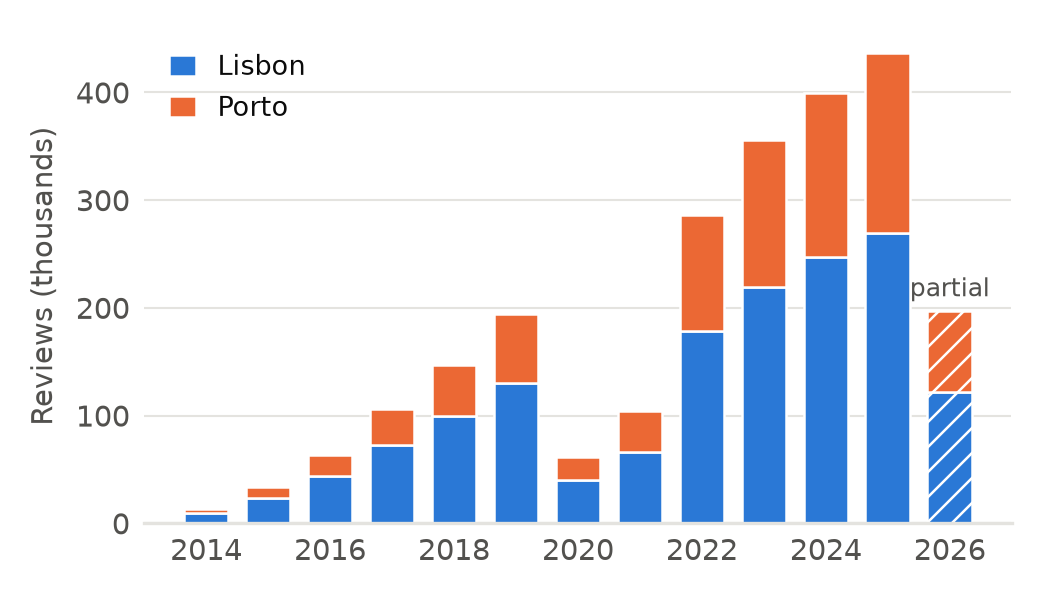

In [5]:
per_year = (reviews.groupby([reviews["date"].dt.year.rename("year"), "city"]).size()
            .unstack("city", fill_value=0).reindex(columns=CITIES))
per_year["total"] = per_year.sum(axis=1)
display(per_year)
per_year.to_csv(TABLES / "reviews_per_year.csv")
last_year = int(reviews["date"].dt.year.max())
complete = per_year.loc[per_year.index < last_year, "total"]
keep("reviews_2019", int(per_year.loc[2019, "total"]))
keep("reviews_2020", int(per_year.loc[2020, "total"]))
keep("peak_year", int(complete.idxmax()))
keep("reviews_peak_year", int(complete.max()))

# Single-column figure for the report: stacked bars, categorical slots 1 and 2 of the palette
FIRST_YEAR = 2014
COLORS = {"lisboa": "#2a78d6", "porto": "#eb6834"}
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 7, "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.labelcolor": MUTED, "text.color": TEXT, "hatch.color": "white", "hatch.linewidth": 0.6})
plot = per_year.loc[per_year.index >= FIRST_YEAR, CITIES] / 1000
fig, ax = plt.subplots(figsize=(3.33, 1.85), dpi=300)
bottom = np.zeros(len(plot))
for city in CITIES:
    bars = ax.bar(plot.index, plot[city], bottom=bottom, width=0.72, color=COLORS[city],
                  edgecolor="white", linewidth=0.6, label=CITY_NAMES[city])
    bars[-1].set_hatch("////")  # the last year is incomplete
    bottom += plot[city].to_numpy()
ax.annotate("partial", (plot.index[-1], bottom[-1]), xytext=(0, 2), textcoords="offset points",
            ha="center", va="bottom", fontsize=6, color=MUTED)
ax.set_ylabel("Reviews (thousands)")
ax.set_xticks(plot.index[::2])
ax.tick_params(length=0)
ax.grid(axis="y", color=GRID, linewidth=0.5)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left", handlelength=1, handleheight=0.8, fontsize=6.5)
fig.tight_layout(pad=0.3)
fig.savefig(FIGURES / "reviews_per_year.png", dpi=300)
plt.show()

### Surroundings of the listings

Number of POIs linked to each listing (within 500 m, the five nearest per category plus every POI with a Wikipedia article), distance to the nearest POI of each category, and how many listings have at least one POI with an article nearby.

In [6]:
pois_per_listing = proximity.groupby("listing_id").size().reindex(listings["id"], fill_value=0)
keep("pois_per_listing_median", pois_per_listing.median())
keep("listings_without_pois", int(pois_per_listing.eq(0).sum()))
keep("listings_with_pois", int(pois_per_listing.gt(0).sum()))

nearest = proximity.groupby(["listing_id", "category"])["distance_m"].min().unstack()
nearest = nearest.reindex(listings["id"])
nearby = pd.DataFrame({
    "median_nearest_m": nearest.median().round(0),
    "listings_with_one_within_500m_pct": (100 * nearest.notna().mean()).round(1),
}).sort_values("median_nearest_m")
display(nearby)
nearby.to_csv(TABLES / "nearest_poi_by_category.csv")
for category, row in nearby.iterrows():
    keep(f"nearest_{category}_median_m", row["median_nearest_m"])
    keep(f"with_{category}_within_500m_pct", row["listings_with_one_within_500m_pct"])

article_pois = proximity[proximity["wikipedia_title"].notna()].groupby("listing_id").size()
article_pois = article_pois.reindex(listings["id"], fill_value=0)
keep("listings_with_article_poi_pct", round(100 * article_pois.gt(0).mean(), 1))
keep("article_pois_per_listing_median", article_pois.median())

,median_nearest_m,listings_with_one_within_500m_pct
category,,
food and drink,43.0,94.9
transport,94.0,96.1
tourism and heritage,102.0,84.6
shops,108.0,90.3
public parking,201.0,70.7
leisure,263.0,73.6


np.float64(5.0)

## 4. Relationships between variables

Spearman correlations, since most variables are skewed. `nearby_pois` and `nearby_article_pois` are the number of linked POIs and of linked POIs with a Wikipedia article.

In [7]:
listings["nearby_pois"] = pois_per_listing.to_numpy()
listings["nearby_article_pois"] = article_pois.to_numpy()
corr_columns = ["price", "accommodates", "bedrooms", "number_of_reviews", "review_scores_rating",
                "nearby_pois", "nearby_article_pois"]
for city in CITIES:
    corr = listings[listings["city"].eq(city)][corr_columns].corr(method="spearman").round(2)
    print(CITY_NAMES[city])
    display(corr)
    corr.to_csv(TABLES / f"spearman_{city}.csv")
    keep(f"corr_price_accommodates_{city}", corr.loc["price", "accommodates"])
    keep(f"corr_price_bedrooms_{city}", corr.loc["price", "bedrooms"])
    keep(f"corr_price_rating_{city}", corr.loc["price", "review_scores_rating"])
    keep(f"corr_price_reviews_{city}", corr.loc["price", "number_of_reviews"])
    keep(f"corr_pois_article_pois_{city}", corr.loc["nearby_pois", "nearby_article_pois"])
    keep(f"corr_pois_reviews_{city}", corr.loc["nearby_pois", "number_of_reviews"])
    keep(f"corr_pois_bedrooms_{city}", corr.loc["nearby_pois", "bedrooms"])

superhost = listings.groupby("host_is_superhost")["review_scores_rating"].median()
keep("rating_median_superhost", superhost.get("t"))
keep("rating_median_not_superhost", superhost.get("f"))

Lisbon


,price,accommodates,bedrooms,number_of_reviews,review_scores_rating,nearby_pois,nearby_article_pois
price,1.00,0.70,0.60,0.08,0.23,0.07,0.10
accommodates,0.70,1.00,0.80,0.07,0.09,-0.07,-0.06
bedrooms,0.60,0.80,1.00,-0.01,0.07,-0.13,-0.13
number_of_reviews,0.08,0.07,-0.01,1.00,-0.00,0.29,0.30
review_scores_rating,0.23,0.09,0.07,-0.00,1.00,-0.13,-0.11
nearby_pois,0.07,-0.07,-0.13,0.29,-0.13,1.00,0.97
nearby_article_pois,0.10,-0.06,-0.13,0.30,-0.11,0.97,1.00


Porto


,price,accommodates,bedrooms,number_of_reviews,review_scores_rating,nearby_pois,nearby_article_pois
price,1.00,0.61,0.59,-0.01,0.18,0.07,0.07
accommodates,0.61,1.00,0.78,0.01,0.03,-0.16,-0.14
bedrooms,0.59,0.78,1.00,-0.00,0.03,-0.25,-0.23
number_of_reviews,-0.01,0.01,-0.00,1.00,-0.08,0.26,0.27
review_scores_rating,0.18,0.03,0.03,-0.08,1.00,-0.05,-0.04
nearby_pois,0.07,-0.16,-0.25,0.26,-0.05,1.00,0.95
nearby_article_pois,0.07,-0.14,-0.23,0.27,-0.04,0.95,1.00


np.float64(4.68)

## 5. Text analysis

Length of each text field, languages of the reviews (detected by the processing script), the amenities, and how often the terms of the search tasks appear in the reviews.

In [8]:
review_words = reviews["comments"].str.split().str.len()
article_words = articles["text"].str.split().str.len()
lengths = pd.DataFrame({
    "listing name": listings["name"].str.split().str.len().describe(percentiles=[.5, .95]),
    "listing description": listings["description"].str.split().str.len().describe(percentiles=[.5, .95]),
    "review": review_words.describe(percentiles=[.5, .95]),
    "Wikipedia article": article_words.describe(percentiles=[.5, .95]),
}).T.round(1)
display(lengths)
lengths.to_csv(TABLES / "text_lengths_words.csv")
keep("review_words_total_millions", round(review_words.sum() / 1e6))
keep("review_words_median", review_words.median())
keep("review_words_p95", review_words.quantile(.95))
keep("name_words_median", lengths.loc["listing name", "50%"])
keep("description_words_median", lengths.loc["listing description", "50%"])
keep("article_words_median", article_words.median())
keep("article_words_max", int(article_words.max()))
keep("articles_portuguese", int(articles["lang"].eq("pt").sum()))
keep("articles_english", int(articles["lang"].eq("en").sum()))

languages = pd.concat({
    "all": reviews["lang"].value_counts(normalize=True),
    **{city: reviews.loc[reviews["city"].eq(city), "lang"].value_counts(normalize=True) for city in CITIES},
}, axis=1).mul(100).round(1)
display(languages.head(10))
languages.to_csv(TABLES / "review_languages_pct.csv")
keep("review_languages", reviews["lang"].nunique())
for lang in languages.index[:5]:
    keep(f"review_lang_pct_{lang}", languages.loc[lang, "all"])

amenity_counts = listings["amenities"].str.len()
keep("amenities_per_listing_median", amenity_counts.median())
keep("distinct_amenities", len({a for amenities in listings["amenities"] for a in amenities}))
display(listings["amenities"].explode().value_counts().head(10))

lowered = reviews["comments"].str.lower()
task_terms = pd.Series({term: round(100 * lowered.str.contains(pattern, regex=True).mean(), 1)
                        for term, pattern in TASK_TERMS.items()}, name="reviews_pct")
display(task_terms)
task_terms.to_csv(TABLES / "task_terms_in_reviews.csv")
for term, share in task_terms.items():
    keep(f"reviews_mentioning_{term}_pct", share)

,count,mean,std,min,50%,95%,max
listing name,30590.0,5.8,2.1,1.0,6.0,9.0,15.0
listing description,30590.0,61.6,21.9,1.0,67.0,87.0,183.0
review,2403239.0,48.3,40.2,1.0,37.0,129.0,1002.0
Wikipedia article,782.0,552.2,823.8,9.0,315.0,1913.0,9084.0


,all,lisboa,porto
lang,,,
en,57.3,60.5,51.7
fr,15.5,14.6,17.0
pt,7.7,7.0,9.0
es,7.6,6.1,10.2
de,5.5,5.5,5.4
it,1.8,1.9,1.6
nl,1.5,1.5,1.6
ko,0.9,0.5,1.4
ru,0.3,0.3,0.3


amenities
Wifi                     28122
Kitchen                  28054
Hot water                27235
Hair dryer               26779
Dishes and silverware    25714
Cooking basics           24725
Hangers                  24590
Bed linens               24383
Essentials               24273
Iron                     24161
Name: count, dtype: int64

quiet               5.7
noise or noisy      3.6
metro               5.2
check-in            7.4
elevator or lift    1.3
dog                 0.3
Name: reviews_pct, dtype: float64

## 6. Values quoted in the report

In [9]:
report_numbers = pd.Series(numbers, name="value").rename_axis("metric")
report_numbers.to_csv(TABLES / "report_numbers.csv")
with pd.option_context("display.max_rows", None):
    display(report_numbers.to_frame())

,value
metric,
documents,30590
documents_lisboa,18872
documents_porto,11718
reviews,2403239
listing_poi_links,897237
named_pois,49615
linked_pois,24908
pois_with_article,828
articles_linked_to_pois,778
